
 OPTIMAL RENEWABLE ENERGY DISTRIBUTION

ENERGY DISTRIBUTION DETAILS
----------------------------------------------
Solar -> Village 1: Generated = 61.22 kW, Delivered = 60.00 kW
Solar -> Village 2: Generated = 10.31 kW, Delivered = 10.00 kW
Solar -> Village 3: Generated = 15.63 kW, Delivered = 15.00 kW
Wind -> Village 2: Generated = 60.61 kW, Delivered = 60.00 kW
Wind -> Village 3: Generated = 35.71 kW, Delivered = 35.00 kW

ENERGY SUMMARY
----------------------------------------------
Solar Generation Used: 87.16 kW
Wind Generation Used: 96.32 kW
Total Energy Generated: 183.48 kW
Total Energy Delivered: 180.00 kW
Total Energy Loss: 3.48 kW
Total Distribution Cost: 1992.80
Minimum Objective Cost: 1996.28

SOURCE CAPACITY STATUS
----------------------------------------------
Solar: Capacity = 110.00 kW, Used = 87.16 kW, Remaining = 22.84 kW
Wind: Capacity = 100.00 kW, Used = 96.32 kW, Remaining = 3.68 kW

VILLAGE DEMAND AND SUPPLY STATUS
----------------------------------------------
V

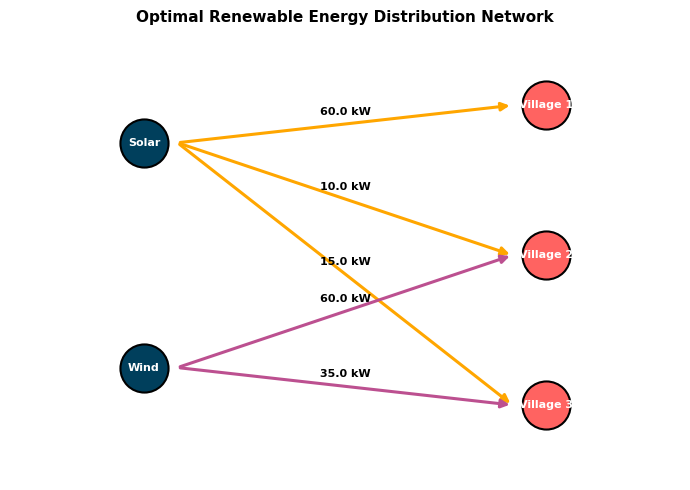

In [6]:
import random
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# ANT COLONY OPTIMIZATION FOR RENEWABLE ENERGY
# DISTRIBUTION OPTIMIZATION
# =====================================================
random.seed(42)
np.random.seed(42)

# STEP 1: Renewable energy generation capacity (kW)
generation = {
    "Solar": 110,
    "Wind": 100
}

# STEP 2: Electricity demand of villages (kW)
demand = {
    "Village 1": 60,
    "Village 2": 70,
    "Village 3": 50
}

sources = list(generation.keys())
villages = list(demand.keys())

# STEP 3: Transmission cost
cost = {
    ("Solar", "Village 1"): 10,
    ("Solar", "Village 2"): 15,
    ("Solar", "Village 3"): 20,
    ("Wind", "Village 1"): 18,
    ("Wind", "Village 2"): 8,
    ("Wind", "Village 3"): 12
}

# STEP 4: Transmission energy loss percentage
loss = {
    ("Solar", "Village 1"): 2,
    ("Solar", "Village 2"): 3,
    ("Solar", "Village 3"): 4,
    ("Wind", "Village 1"): 3,
    ("Wind", "Village 2"): 1,
    ("Wind", "Village 3"): 2
}

# STEP 5: ACO PARAMETERS
num_ants = 30
iterations = 100
alpha = 1.0
beta = 2.0
rho = 0.5
Q = 100
lam = 1.0
chunk_size = 5.0
epsilon = 0.000001

# STEP 6: INITIALIZE PHEROMONE
pheromone = {
    (s, v): 1.0 for s in sources for v in villages
}

best_plan = None
best_cost = float("inf")
convergence = []
iteration_best = []

# =====================================================
# STEP 7: ACO MAIN LOOP
# =====================================================
for iteration in range(iterations):
    iteration_plans = []
    current_best = float("inf")

    for ant in range(num_ants):
        remaining = generation.copy()
        remaining_demand = demand.copy()
        plan = []
        total_cost = 0.0
        total_loss = 0.0
        feasible = True

        # Distribute energy to each village
        for v in villages:
            while remaining_demand[v] > epsilon:
                choices = []
                delivered = min(chunk_size, remaining_demand[v])

                # Find available energy sources
                for s in sources:
                    loss_rate = loss[(s, v)] / 100.0
                    required = delivered / (1 - loss_rate)

                    if remaining[s] + epsilon >= required:
                        visibility = 1.0 / (cost[(s, v)] + lam * loss[(s, v)])
                        score = (pheromone[(s, v)] ** alpha) * (visibility ** beta)
                        choices.append((s, score))

                # No source available
                if not choices:
                    feasible = False
                    break

                # Roulette wheel selection
                total_score = sum(score for s, score in choices)
                r = random.uniform(0, total_score)
                selected = choices[-1]
                for s, score in choices:
                    r -= score
                    if r <= 0:
                        selected = s
                        break

                # Calculate allocated and delivered energy
                loss_rate = loss[(selected, v)] / 100.0
                allocated = delivered / (1 - loss_rate)
                actual_loss = allocated - delivered

                # Update available generation
                remaining[selected] -= allocated

                # Update village demand
                remaining_demand[v] -= delivered

                # Avoid small floating-point errors
                if remaining_demand[v] < epsilon:
                    remaining_demand[v] = 0.0

                # Store allocation plan
                plan.append((selected, v, allocated, delivered))

                # Calculate cost and transmission loss
                total_cost += (allocated * cost[(selected, v)])
                total_loss += actual_loss

            if not feasible:
                break

        # STEP 8: CHECK FEASIBILITY
        if feasible and all(remaining_demand[v] <= epsilon for v in villages):
            objective = total_cost + lam * total_loss
            iteration_plans.append((objective, plan.copy()))

            if objective < current_best:
                current_best = objective

            if objective < best_cost:
                best_cost = objective
                best_plan = plan.copy()

    # =================================================
    # STEP 9: PHEROMONE EVAPORATION
    # =================================================
    for edge in pheromone:
        pheromone[edge] *= (1 - rho)

    # =================================================
    # STEP 10: PHEROMONE DEPOSITION
    # =================================================
    for objective, plan in iteration_plans:
        for s, v, allocated, delivered in plan:
            pheromone[(s, v)] += (Q * delivered / objective)

    # Store convergence values
    iteration_best.append(current_best if current_best != float("inf") else np.nan)
    convergence.append(best_cost)

# =====================================================
# STEP 11: DISPLAY OPTIMAL DISTRIBUTION
# =====================================================
print("\n==============================================")
print(" OPTIMAL RENEWABLE ENERGY DISTRIBUTION")
print("==============================================")

if best_plan is None:
    print("No feasible distribution plan found.")
    raise SystemExit

# Initialize allocation
allocation = {(s, v): [0.0, 0.0] for s in sources for v in villages}

# Aggregate energy allocation
for s, v, allocated, delivered in best_plan:
    allocation[(s, v)][0] += allocated
    allocation[(s, v)][1] += delivered

# =====================================================
# STEP 12: DISTRIBUTION DETAILS
# =====================================================
print("\nENERGY DISTRIBUTION DETAILS")
print("----------------------------------------------")
for s in sources:
    for v in villages:
        allocated, delivered = allocation[(s, v)]
        if delivered > epsilon:
            print(f"{s} -> {v}: Generated = {allocated:.2f} kW, Delivered = {delivered:.2f} kW")

# =====================================================
# STEP 13: ENERGY SUMMARY
# =====================================================
solar_used = sum(allocation[("Solar", v)][0] for v in villages)
wind_used = sum(allocation[("Wind", v)][0] for v in villages)
total_generated = solar_used + wind_used
total_delivered = sum(allocation[(s, v)][1] for s in sources for v in villages)
total_energy_loss = total_generated - total_delivered
total_distribution_cost = sum(allocation[(s, v)][0] * cost[(s, v)] for s in sources for v in villages)

print("\nENERGY SUMMARY")
print("----------------------------------------------")
print(f"Solar Generation Used: {solar_used:.2f} kW")
print(f"Wind Generation Used: {wind_used:.2f} kW")
print(f"Total Energy Generated: {total_generated:.2f} kW")
print(f"Total Energy Delivered: {total_delivered:.2f} kW")
print(f"Total Energy Loss: {total_energy_loss:.2f} kW")
print(f"Total Distribution Cost: {total_distribution_cost:.2f}")
print(f"Minimum Objective Cost: {best_cost:.2f}")

# =====================================================
# STEP 14: SOURCE CAPACITY STATUS
# =====================================================
print("\nSOURCE CAPACITY STATUS")
print("----------------------------------------------")
for s in sources:
    used = sum(allocation[(s, v)][0] for v in villages)
    print(f"{s}: Capacity = {generation[s]:.2f} kW, Used = {used:.2f} kW, Remaining = {generation[s] - used:.2f} kW")

# =====================================================
# STEP 15: VILLAGE DEMAND AND SUPPLY STATUS
# =====================================================
print("\nVILLAGE DEMAND AND SUPPLY STATUS")
print("----------------------------------------------")
for v in villages:
    supplied = sum(allocation[(s, v)][1] for s in sources)
    shortage = max(0.0, demand[v] - supplied)
    print(f"{v}: Demand = {demand[v]:.2f} kW, Supplied = {supplied:.2f} kW, Shortage = {shortage:.2f} kW")

print("\nOptimization Completed Successfully!")

# =====================================================
# STEP 16: DISTRIBUTION NETWORK GRAPH (MEDIUM SIZE)
# =====================================================
fig, ax1 = plt.subplots(figsize=(7, 5))

pos = {
    "Solar": (1, 4),
    "Wind": (1, 1),
    "Village 1": (4, 4.5),
    "Village 2": (4, 2.5),
    "Village 3": (4, 0.5)
}

# Draw source and village nodes
for node, (x, y) in pos.items():
    node_color = "#003f5c" if node in sources else "#ff6361"
    ax1.scatter(x, y, s=1200, color=node_color, edgecolors="black", linewidths=1.5, zorder=3)
    ax1.text(x, y, node, ha="center", va="center", color="white", fontweight="bold", fontsize=8)

# Draw energy distribution arrows
for s in sources:
    for v in villages:
        allocated, delivered = allocation[(s, v)]
        if delivered > epsilon:
            x1, y1 = pos[s]
            x2, y2 = pos[v]
            arrow_properties = dict(arrowstyle="-|>", color=("#ffa600" if s == "Solar" else "#bc5090"), lw=2.2, mutation_scale=12)
            ax1.annotate("", xy=(x2 - 0.25, y2), xytext=(x1 + 0.25, y1), arrowprops=arrow_properties)
            ax1.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.12, f"{delivered:.1f} kW", ha="center", fontsize=8, fontweight="bold")

ax1.set_title("Optimal Renewable Energy Distribution Network", fontsize=11, fontweight="bold")
ax1.set_xlim(0, 5)
ax1.set_ylim(-0.5, 5.5)
ax1.axis("off")

plt.tight_layout()
plt.show()
